<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/03%20-%20Unsupervised%20Learning/solutions/03_exercises_solutions.ipynb)

# 03d — 第三讲基础习题参考答案（Solutions）

本文件对应 `03d_exercises.ipynb` 中全部 8 道无监督学习基础巩固习题的完整参考代码与解析。

In [1]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "03 - Unsupervised Learning/solutions"))
    get_ipython().run_line_magic("pip", "install -q rdkit")


---

## 0. 公共环境与分子特征准备

In [2]:
import os
os.environ["MKL_NUM_THREADS"] = "1"
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, Draw, rdFingerprintGenerator
from rdkit.ML.Cluster import Butina

RDLogger.DisableLog("rdApp.*")
plt.rcParams["figure.dpi"] = 110

for p in ["../data/solubility.csv", "data/solubility.csv", "solubility.csv"]:
    if os.path.exists(p):
        df = pd.read_csv(p)
        break

df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)

feature_cols = [
    "MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
    "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
    "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA",
    "BalabanJ", "BertzCT",
]

df_sub = df.iloc[:1000].copy().reset_index(drop=True)
X_raw = df_sub[feature_cols]
y_sub = df_sub["Solubility"].values
print(f"成功准备练习子集 df_sub: {X_raw.shape}")

成功准备练习子集 df_sub: (1000, 17)


<!-- ai4m-style -->
> **📘 课程统一绘图风格**：下面这格加载课程自带的 `ai4m.mplstyle`（配色与课程网站同源，无上右边框，仅横向浅网格，保存默认 300 dpi）。`C` 是课程配色，手动指定颜色时写 `color=C.crimson`。


In [3]:
# ai4m-style：课程统一绘图风格（本地与 Colab 通用）
import pathlib, sys

sys.path.insert(0, str(pathlib.Path.cwd().parent.parent))   # course/ 根目录
import ai4m_style as ai4m

C = ai4m.use()        # 应用 ai4m.mplstyle，返回课程配色


---

## 第一部分：主成分分析（PCA）与新分子投影（对应 `03a`）

### 习题 1：特征标准化与 PCA 解释方差比

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

pca = PCA().fit(X_scaled)
pcs = pca.transform(X_scaled)

print("前 3 个主成分解释方差比:", pca.explained_variance_ratio_[:3].round(3))
print("前 3 个主成分累计解释方差比:", pca.explained_variance_ratio_[:3].sum().round(3))

前 3 个主成分解释方差比: [0.536 0.148 0.123]
前 3 个主成分累计解释方差比: 0.806


### 习题 2：找出对 PC1 和 PC2 贡献最大的前 3 个描述符

In [5]:
loadings = pd.DataFrame(pca.components_[:2].T, index=feature_cols, columns=["PC1", "PC2"])

print("=== 对 PC1 载荷绝对值最大的 Top-3 描述符（分子尺寸）===")
print(loadings["PC1"].abs().nlargest(3).round(3))

print("\n=== 对 PC2 载荷绝对值最大的 Top-3 描述符（极性 vs 亲油）===")
print(loadings["PC2"].abs().nlargest(3).round(3))

=== 对 PC1 载荷绝对值最大的 Top-3 描述符（分子尺寸）===
LabuteASA              0.323
HeavyAtomCount         0.323
NumValenceElectrons    0.315
Name: PC1, dtype: float64

=== 对 PC2 载荷绝对值最大的 Top-3 描述符（极性 vs 亲油）===
MolLogP              0.488
NumSaturatedRings    0.396
NumAliphaticRings    0.380
Name: PC2, dtype: float64


### 习题 3：绘制二维 PCA 散点图并将新分子投影上去

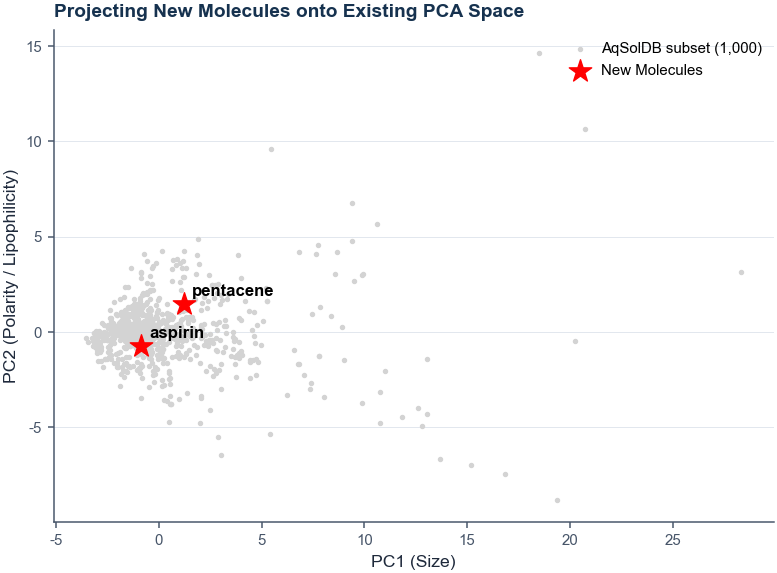

In [6]:
new_smiles = {
    "aspirin":   "CC(=O)Oc1ccccc1C(=O)O",
    "pentacene": "c1ccc2cc3cc4cc5ccccc5cc4cc3cc2c1",
}
new_mols_df = pd.DataFrame(
    [[getattr(Descriptors, col)(Chem.MolFromSmiles(s)) for col in feature_cols] for s in new_smiles.values()],
    columns=feature_cols,
    index=list(new_smiles.keys()),
)

new_pcs = pca.transform(scaler.transform(new_mols_df))

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.scatter(pcs[:, 0], pcs[:, 1], s=6, color="lightgray", label="AqSolDB subset (1,000)")
ax.scatter(new_pcs[:, 0], new_pcs[:, 1], marker="*", s=200, color="red", zorder=5, label="New Molecules")
for name, (x, y) in zip(new_mols_df.index, new_pcs[:, :2]):
    ax.annotate(name, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=10, weight="bold")
ax.set_xlabel("PC1 (Size)")
ax.set_ylabel("PC2 (Polarity / Lipophilicity)")
ax.set_title("Projecting New Molecules onto Existing PCA Space")
ax.legend()
plt.show()

---

## 第二部分：K-means、轮廓系数与 Butina 分子聚类（对应 `03b`）

### 习题 4：运行 K-means 并统计各簇分子数与平均溶解度

In [7]:
from sklearn.cluster import KMeans

km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_scaled)
df_sub["cluster"] = km3.labels_

df_sub.groupby("cluster")[["MolWt", "MolLogP", "Solubility"]].agg(["count", "mean"]).round(2)

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


MolWt         MolLogP       Solubility      
        count    mean   count  mean      count  mean
cluster                                             
0         193  411.93     193  2.17        193 -3.72
1          42  909.86      42  5.41         42 -3.72
2         765  186.77     765  2.20        765 -3.02

### 习题 5：计算不同簇数 $k$ 下的轮廓系数（Silhouette Score）

In [8]:
from sklearn.metrics import silhouette_score

for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    score = silhouette_score(X_scaled, km.labels_)
    print(f"k = {k}: Silhouette Score = {score:.3f}")

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


k = 2: Silhouette Score = 0.616
k = 3: Silhouette Score = 0.398
k = 4: Silhouette Score = 0.391
k = 5: Silhouette Score = 0.393
k = 6: Silhouette Score = 0.360


### 习题 6：使用 RDKit Taylor-Butina 算法对分子指纹聚类

总簇数: 245 | 最大簇包含分子数: 6


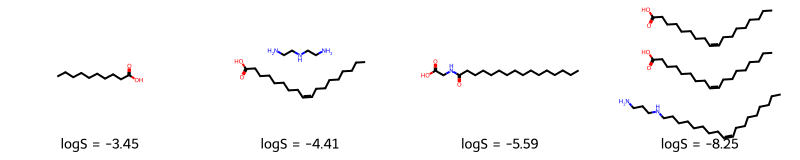

In [9]:
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
mols_300 = df_sub["mol"].iloc[:300].tolist()
fps_300 = [fp_gen.GetFingerprint(m) for m in mols_300]

dists_300 = []
for i in range(1, len(fps_300)):
    sims = DataStructs.BulkTanimotoSimilarity(fps_300[i], fps_300[:i])
    dists_300.extend(1.0 - np.array(sims))

clusters = Butina.ClusterData(dists_300, len(fps_300), 0.5, isDistData=True)
print(f"总簇数: {len(clusters)} | 最大簇包含分子数: {len(clusters[0])}")

top4_idx = list(clusters[0][:4])
Draw.MolsToGridImage(
    [mols_300[i] for i in top4_idx],
    molsPerRow=4,
    subImgSize=(200, 160),
    legends=[f"logS = {df_sub['Solubility'].iloc[i]:.2f}" for i in top4_idx],
)

---

## 第三部分：按簇交叉验证与膦配体近邻查找（对应 `03b` & `03c`）

### 习题 7：对比普通 `KFold` 与按簇分组 `GroupKFold` 的回归误差

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold, cross_val_score

groups = KMeans(n_clusters=10, n_init=10, random_state=42).fit_predict(X_scaled)
rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)

rmse_rand = -cross_val_score(
    rf, X_raw, y_sub,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring="neg_root_mean_squared_error",
).mean()

rmse_grp = -cross_val_score(
    rf, X_raw, y_sub,
    cv=list(GroupKFold(n_splits=5).split(X_raw, y_sub, groups)),
    scoring="neg_root_mean_squared_error",
).mean()

print(f"Random 5-Fold RMSE = {rmse_rand:.3f} | Cluster 5-Fold RMSE = {rmse_grp:.3f}")

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


Random 5-Fold RMSE = 1.036 | Cluster 5-Fold RMSE = 1.237


### 习题 8：在 LKB-P 膦配体数据库中查找 16 号正例配体的最近邻

In [11]:
for p in ["../data/LKB_P.csv", "data/LKB_P.csv", "LKB_P.csv"]:
    if os.path.exists(p):
        ligands = pd.read_csv(p, sep=";", index_col=0)
        break

drop_cols = ["Type", "PC1", "PC2", "PC3", "PC4"]
X_lkb = pd.DataFrame(
    StandardScaler().fit_transform(ligands.drop(columns=drop_cols)),
    index=ligands.index,
)

dists = pd.Series(
    np.linalg.norm(X_lkb.values - X_lkb.loc[16].values, axis=1),
    index=X_lkb.index,
    name="Euclidean_Dist_to_#16",
)
nearest6_ids = dists.nsmallest(6).index
result_df = ligands.loc[nearest6_ids, ["Type", "E(HOMO)", "He8_steric", "PA"]].copy()
result_df["Dist_to_#16"] = dists.loc[nearest6_ids].round(3)
result_df

,Type,E(HOMO),He8_steric,PA,Dist_to_#16
No.,,,,,
16,R,-0.17267,23.38,250.80,0.000
45,R,-0.17060,30.37,253.62,1.340
41,R,-0.17250,20.96,250.18,1.458
55,R,-0.16900,32.18,256.19,1.620
317,R,-0.16380,34.68,255.41,3.107
43,R,-0.17270,22.86,250.62,3.510
